# Real Estate Property Market Analysis 

## Business Problem

Hyderabad's growing residential real estate market offers properties across various localities, BHK configurations, and price ranges. However, differences in property size, location, furnishing status, and other characteristics make it difficult for prospective buyers to compare properties and understand pricing patterns.

Without analysing actual property listing data, identifying affordable localities, understanding price variations, and examining relationships between property features can be challenging.

This project addresses the problem by collecting residential property listings from MagicBricks and analysing them to uncover meaningful patterns, compare locality-wise prices, and understand the characteristics influencing the residential property market.

## Objectives

Collect real-world residential property data from MagicBricks using web scraping.

Analyse property pricing patterns and locality-wise variations.

Explore relationships between property characteristics and prices.

Apply statistical analysis to derive meaningful market insights.

In [7]:
# Import necesary libraries

In [2]:

from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.common.exceptions import (
    TimeoutException,
    StaleElementReferenceException,
    WebDriverException
)
import pandas as pd
import re
import time
import os




In [8]:
# Open chrome using selenium

In [2]:

options = webdriver.ChromeOptions()
options.add_argument("--start-maximized")

driver = webdriver.Chrome(options=options)
wait = WebDriverWait(driver, 25)

print("Chrome opened successfully!")


Chrome opened successfully!


In [9]:
# Open website

In [3]:

url = "https://www.magicbricks.com/property-for-sale/residential-real-estate?bedroom=&proptype=Multistorey-Apartment,Builder-Floor-Apartment,Penthouse,Studio-Apartment&cityName=Hyderabad"

driver.get(url)

wait.until(
    EC.presence_of_element_located(
        (By.CSS_SELECTOR, "h2.mb-srp__card--title")
    )
)

print("Website opened successfully!")
print("Page title:", driver.title)
print("Current URL:", driver.current_url)


Website opened successfully!
Page title: Flats for Sale in Hyderabad: 23479+ Apartments / Flats in Hyderabad
Current URL: https://www.magicbricks.com/property-for-sale/residential-real-estate?bedroom=&proptype=Multistorey-Apartment,Builder-Floor-Apartment,Penthouse,Studio-Apartment&cityName=Hyderabad


In [10]:
# Load the  property page listings

In [4]:

titles = driver.find_elements(
    By.CSS_SELECTOR,
    "h2.mb-srp__card--title"
)

print("Initial property titles loaded:", len(titles))
print("Page height:", driver.execute_script(
    "return document.documentElement.scrollHeight"
))
print("Current URL:", driver.current_url)


Initial property titles loaded: 30
Page height: 8458
Current URL: https://www.magicbricks.com/property-for-sale/residential-real-estate?bedroom=&proptype=Multistorey-Apartment,Builder-Floor-Apartment,Penthouse,Studio-Apartment&cityName=Hyderabad


In [11]:
# Load 1000 plus  records 

In [5]:

import time
from selenium.webdriver.common.by import By

target = 1200
selector = "h2.mb-srp__card--title"

stalled_rounds = 0
max_stalled_rounds = 15
previous_count = len(
    driver.find_elements(By.CSS_SELECTOR, selector)
)

while previous_count < target and stalled_rounds < max_stalled_rounds:

    # Scroll to the bottom to trigger MagicBricks loading
    driver.execute_script(
        "window.scrollTo(0, document.body.scrollHeight);"
    )
    time.sleep(2.5)

    current_count = len(
        driver.find_elements(By.CSS_SELECTOR, selector)
    )

    if current_count > previous_count:
        previous_count = current_count
        stalled_rounds = 0
    else:
        stalled_rounds += 1

print("Final loaded titles:", previous_count)

if previous_count >= target:
    print("Target reached. Ready for extraction.")
else:
    print("Loading stalled before target; do not restart Chrome.")


Final loaded titles: 1230
Target reached. Ready for extraction.


In [12]:
# Extract the information using regex patterns and store in a data frame

In [6]:

import pandas as pd
import re
from selenium.webdriver.common.by import By
from selenium.common.exceptions import StaleElementReferenceException

def get_label_value(text, label):
    pattern = rf"(?im)^\s*{re.escape(label)}\s*\n\s*([^\n]+)"
    match = re.search(pattern, text)
    return match.group(1).strip() if match else None

def get_price(text):
    match = re.search(
        r"₹\s*([\d,]+(?:\.\d+)?)\s*(Crore|Cr|Lacs?|Lakhs?)\b",
        text, re.I
    )
    if not match:
        return None
    amount = float(match.group(1).replace(",", ""))
    return amount * (10000000 if match.group(2).lower() in ("cr", "crore") else 100000)

def get_price_per_sqft(text):
    match = re.search(
        r"₹\s*([\d,]+(?:\.\d+)?)\s*per\s*(?:sq\.?\s*ft|sqft)\b",
        text, re.I
    )
    return float(match.group(1).replace(",", "")) if match else None

def get_area(text):
    match = re.search(
        r"(?im)^\s*(Super Area|Carpet Area|Built[- ]?up Area)\s*\n"
        r"\s*([\d,]+(?:\.\d+)?)\s*(?:sq\.?\s*ft|sqft)\b",
        text
    )
    if match:
        return match.group(1), float(match.group(2).replace(",", ""))
    return None, None

def parse_property(text):
    lines = [line.strip() for line in text.splitlines() if line.strip()]

    heading_match = re.search(
        r"(?im)^\s*((?:\d+\s*BHK\s+)?(?:Flat|Apartment|Villa|House|Plot)"
        r"\s+for\s+Sale\s+in\s+[^\n]+)",
        text
    )
    heading = heading_match.group(1).strip() if heading_match else None

    # Prefer the first plausible project-name line after the listing heading.
    property_name = None
    if heading in lines:
        idx = lines.index(heading)
        for line in lines[idx + 1:]:
            if re.search(
                r"^(Super Area|Carpet Area|Built[- ]?up Area|Transaction|"
                r"Furnishing|Bathroom|Balcony|Under Construction|Poss\.|₹)",
                line, re.I
            ):
                continue
            if line.lower().startswith(("photos", "buy ", "posted:", "popular project")):
                continue
            property_name = line
            break

    bhk_match = re.search(r"\b(\d+)\s*BHK\b", heading or "", re.I)
    bhk = int(bhk_match.group(1)) if bhk_match else None

    location_match = re.search(
        r"\bfor\s+Sale\s+in\s+(.+?)(?:,\s*Hyderabad)?\s*$",
        heading or "", re.I
    )
    location = location_match.group(1).strip(" ,") if location_match else None

    if re.search(r"\bVilla\b", heading or "", re.I):
        property_type = "Villa"
    elif re.search(r"\bPlot\b", heading or "", re.I):
        property_type = "Plot/Land"
    elif re.search(r"\bHouse\b", heading or "", re.I):
        property_type = "Residential House"
    elif re.search(r"\b(Flat|Apartment)\b", heading or "", re.I):
        property_type = "Apartment"
    else:
        property_type = None

    area_type, area_sqft = get_area(text)

    return {
        "property_name": property_name,
        "property_type": property_type,
        "location": location,
        "price": get_price(text),
        "price_per_sqft": get_price_per_sqft(text),
        "area_type": area_type,
        "area_sqft": area_sqft,
        "bhk": bhk,
        "furnishing": get_label_value(text, "Furnishing"),
        "bathrooms": pd.to_numeric(get_label_value(text, "Bathroom"), errors="coerce"),
        "balconies": pd.to_numeric(get_label_value(text, "Balcony"), errors="coerce")
    }

cards = driver.find_elements(By.CSS_SELECTOR, "div.mb-srp__card")
print("Property cards currently available:", len(cards))

property_data = []
for i, card in enumerate(cards, start=1):
    try:
        text = card.text.strip()
        if text:
            property_data.append(parse_property(text))
        if i % 50 == 0:
            print(f"Processed {i}/{len(cards)} cards | Records extracted: {len(property_data)}")
    except StaleElementReferenceException:
        print(f"Card {i} changed while extracting; skipped.")

df = pd.DataFrame(property_data, columns=[
    "property_name", "property_type", "location", "price",
    "price_per_sqft", "area_type", "area_sqft", "bhk",
    "furnishing", "bathrooms", "balconies"
])

df.to_csv("magicbricks_hyderabad_properties.csv", index=False)

print("\nExtraction finished.")
print("DataFrame shape:", df.shape)
print("Records saved:", len(df))
display(df.head(10))


Property cards currently available: 1290
Processed 50/1290 cards | Records extracted: 50
Processed 100/1290 cards | Records extracted: 100
Processed 150/1290 cards | Records extracted: 150
Processed 200/1290 cards | Records extracted: 200
Processed 250/1290 cards | Records extracted: 250
Processed 300/1290 cards | Records extracted: 300
Processed 350/1290 cards | Records extracted: 350
Processed 400/1290 cards | Records extracted: 400
Processed 450/1290 cards | Records extracted: 450
Processed 500/1290 cards | Records extracted: 500
Processed 550/1290 cards | Records extracted: 550
Processed 600/1290 cards | Records extracted: 600
Processed 650/1290 cards | Records extracted: 650
Processed 700/1290 cards | Records extracted: 700
Processed 750/1290 cards | Records extracted: 750
Processed 800/1290 cards | Records extracted: 800
Processed 850/1290 cards | Records extracted: 850
Processed 900/1290 cards | Records extracted: 900
Processed 950/1290 cards | Records extracted: 950
Processed 1

,property_name,property_type,location,price,price_per_sqft,area_type,area_sqft,bhk,furnishing,bathrooms,balconies
0,Teja Fortune Heights,Apartment,Patancheruvu,9100000.0,5199.0,SUPER AREA,1750.0,3.0,Unfurnished,3.0,1.0
1,Aditya Athena,Apartment,Shaikpet,22000000.0,12429.0,SUPER AREA,1770.0,3.0,Unfurnished,3.0,2.0
2,Prestige Golden Grove,Apartment,"Tellapur, Outer Ring Road",30000000.0,9989.0,SUPER AREA,3010.0,4.0,Unfurnished,4.0,2.0
3,Silpa Vaibhavi Vihanga,Apartment,"Tellapur, Outer Ring Road",12500000.0,6480.0,SUPER AREA,1930.0,3.0,Unfurnished,3.0,2.0
4,Sonthalia Fortune Sky Villas,Apartment,"Kokapet, Outer Ring Road",92600000.0,12632.0,SUPER AREA,7333.0,4.0,Unfurnished,4.0,2.0
5,MSR Mamidi Prive 32,Apartment,Rajendranagar Mandal,19100000.0,7499.0,SUPER AREA,2560.0,3.0,Unfurnished,3.0,2.0
6,Prestige Golden Grove,Apartment,"Tellapur, Outer Ring Road",28900000.0,9989.0,CARPET AREA,1826.0,4.0,Unfurnished,4.0,2.0
7,De Blueoak The Trilight,Apartment,"Kokapet, Outer Ring Road",44700000.0,11500.0,SUPER AREA,3888.0,4.0,Unfurnished,4.0,3.0
8,Prestige Golden Grove,Apartment,"Tellapur, Outer Ring Road",30000000.0,9989.0,SUPER AREA,3010.0,4.0,Unfurnished,4.0,2.0
9,Prestige Golden Grove,Apartment,"Tellapur, Outer Ring Road",30000000.0,9989.0,SUPER AREA,3010.0,4.0,Unfurnished,4.0,2.0


In [13]:
# Quit the browser 

In [7]:
driver.quit()

In [14]:
# Load the data frame we extracted  and perform EDA

In [8]:
df=pd.read_csv("magicbricks_hyderabad_properties.csv")

In [9]:
df.head()

,property_name,property_type,location,price,price_per_sqft,area_type,area_sqft,bhk,furnishing,bathrooms,balconies
0,Teja Fortune Heights,Apartment,Patancheruvu,9100000.0,5199.0,SUPER AREA,1750.0,3.0,Unfurnished,3.0,1.0
1,Aditya Athena,Apartment,Shaikpet,22000000.0,12429.0,SUPER AREA,1770.0,3.0,Unfurnished,3.0,2.0
2,Prestige Golden Grove,Apartment,"Tellapur, Outer Ring Road",30000000.0,9989.0,SUPER AREA,3010.0,4.0,Unfurnished,4.0,2.0
3,Silpa Vaibhavi Vihanga,Apartment,"Tellapur, Outer Ring Road",12500000.0,6480.0,SUPER AREA,1930.0,3.0,Unfurnished,3.0,2.0
4,Sonthalia Fortune Sky Villas,Apartment,"Kokapet, Outer Ring Road",92600000.0,12632.0,SUPER AREA,7333.0,4.0,Unfurnished,4.0,2.0


In [15]:
# Data Understanding

In [10]:
df.shape

(1290, 11)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1290 entries, 0 to 1289
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   property_name   1271 non-null   object 
 1   property_type   1271 non-null   object 
 2   location        1271 non-null   object 
 3   price           1290 non-null   float64
 4   price_per_sqft  1245 non-null   float64
 5   area_type       1287 non-null   object 
 6   area_sqft       1287 non-null   float64
 7   bhk             1270 non-null   float64
 8   furnishing      460 non-null    object 
 9   bathrooms       302 non-null    float64
 10  balconies       59 non-null     float64
dtypes: float64(6), object(5)
memory usage: 111.0+ KB


In [12]:
df.describe()

,price,price_per_sqft,area_sqft,bhk,bathrooms,balconies
count,1.290000e+03,1.245000e+03,1287.000000,1270.000000,302.000000,59.000000
mean,2.318822e+07,1.285814e+04,1866.891997,2.888189,2.834437,2.254237
std,1.173844e+08,1.224269e+05,1066.134732,0.657216,0.793918,1.060143
min,1.800000e+06,2.413000e+03,20.000000,1.000000,1.000000,1.000000
25%,1.060000e+07,6.857000e+03,1250.000000,2.000000,2.000000,2.000000
50%,1.500000e+07,8.799000e+03,1600.000000,3.000000,3.000000,2.000000
75%,2.287500e+07,1.091600e+04,2099.000000,3.000000,3.000000,3.000000
max,4.085000e+09,4.300001e+06,13350.000000,5.000000,6.000000,6.000000


In [13]:
df = df.reset_index(drop=True)

In [14]:
df.head()

,property_name,property_type,location,price,price_per_sqft,area_type,area_sqft,bhk,furnishing,bathrooms,balconies
0,Teja Fortune Heights,Apartment,Patancheruvu,9100000.0,5199.0,SUPER AREA,1750.0,3.0,Unfurnished,3.0,1.0
1,Aditya Athena,Apartment,Shaikpet,22000000.0,12429.0,SUPER AREA,1770.0,3.0,Unfurnished,3.0,2.0
2,Prestige Golden Grove,Apartment,"Tellapur, Outer Ring Road",30000000.0,9989.0,SUPER AREA,3010.0,4.0,Unfurnished,4.0,2.0
3,Silpa Vaibhavi Vihanga,Apartment,"Tellapur, Outer Ring Road",12500000.0,6480.0,SUPER AREA,1930.0,3.0,Unfurnished,3.0,2.0
4,Sonthalia Fortune Sky Villas,Apartment,"Kokapet, Outer Ring Road",92600000.0,12632.0,SUPER AREA,7333.0,4.0,Unfurnished,4.0,2.0


In [15]:
print(df.columns.tolist())
print("Shape:", df.shape)

['property_name', 'property_type', 'location', 'price', 'price_per_sqft', 'area_type', 'area_sqft', 'bhk', 'furnishing', 'bathrooms', 'balconies']
Shape: (1290, 11)


In [16]:
df.duplicated().sum()

np.int64(8)

In [17]:
df=df.drop_duplicates()

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df.isna().sum()

property_name       19
property_type       19
location            19
price                0
price_per_sqft      45
area_type            3
area_sqft            3
bhk                 20
furnishing         827
bathrooms          985
balconies         1228
dtype: int64

In [20]:
df = df.dropna(
    subset=["property_name", "property_type", "location"]
).copy()

In [21]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

display(missing_summary.round(2))

,Missing Values,Missing Percentage
property_name,0,0.00
property_type,0,0.00
location,0,0.00
price,0,0.00
price_per_sqft,45,3.56
area_type,3,0.24
area_sqft,3,0.24
bhk,1,0.08
furnishing,819,64.85
bathrooms,972,76.96


In [22]:
df["area_type"] = df["area_type"].fillna("Unknown")

print("Missing area types:", df["area_type"].isna().sum())
print("Missing area values:", df["area_sqft"].isna().sum())

Missing area types: 0
Missing area values: 3


In [23]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nCurrent dataset shape:", df.shape)

Missing values in each column:
property_name        0
property_type        0
location             0
price                0
price_per_sqft      45
area_type            0
area_sqft            3
bhk                  1
furnishing         819
bathrooms          972
balconies         1210
dtype: int64

Current dataset shape: (1263, 11)


In [24]:
# Fill missing furnishing details
df["furnishing"] = df["furnishing"].fillna("Unknown")

# Check missing values again
print(df.isnull().sum())

property_name        0
property_type        0
location             0
price                0
price_per_sqft      45
area_type            0
area_sqft            3
bhk                  1
furnishing           0
bathrooms          972
balconies         1210
dtype: int64


In [25]:
# Numeric columns
numeric_cols = ["price", "price_per_sqft", "area_sqft"]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Count columns that may contain missing values
count_cols = ["bhk", "bathrooms", "balconies"]

for col in count_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce").round().astype("Int64")

print(df.dtypes)

property_name      object
property_type      object
location           object
price             float64
price_per_sqft    float64
area_type          object
area_sqft         float64
bhk                 Int64
furnishing         object
bathrooms           Int64
balconies           Int64
dtype: object


In [26]:
df.isna().sum()

property_name        0
property_type        0
location             0
price                0
price_per_sqft      45
area_type            0
area_sqft            3
bhk                  1
furnishing           0
bathrooms          972
balconies         1210
dtype: int64

In [28]:
df['area_sqft']=df['area_sqft'].fillna(df['area_sqft'].median())

In [29]:
df['bhk']=df['bhk'].fillna(df['bhk'].median())

In [30]:
df.isna().sum()

property_name        0
property_type        0
location             0
price                0
price_per_sqft      45
area_type            0
area_sqft            0
bhk                  0
furnishing           0
bathrooms          972
balconies         1210
dtype: int64

In [31]:
# Find rows where price per sqft is missing
# but price and area are available and valid
mask = (
    df["price_per_sqft"].isna()
    & df["price"].notna()
    & df["area_sqft"].notna()
    & (df["area_sqft"] > 0)
)

# Calculate price per sqft for those rows
df.loc[mask, "price_per_sqft"] = (
    df.loc[mask, "price"] / df.loc[mask, "area_sqft"]
)

print("Values filled:", mask.sum())
print("Missing values remaining:", df["price_per_sqft"].isna().sum())

Values filled: 45
Missing values remaining: 0


In [38]:
df.drop(columns='balconies',inplace=True)

In [33]:
print("Bathroom count distribution:")
print(df["bathrooms"].value_counts().sort_index())

print("\nMost common bathroom count:")
print(df["bathrooms"].mode())

Bathroom count distribution:
bathrooms
1      3
2     99
3    147
4     33
5      8
6      1
Name: count, dtype: Int64

Most common bathroom count:
0    3
Name: bathrooms, dtype: Int64


In [34]:
df['bathrooms'].median()

np.float64(3.0)

In [35]:
# Check median bathrooms for each BHK group
print(df.groupby("bhk")["bathrooms"].median())

bhk
1    1.5
2    2.0
3    3.0
4    4.0
5    5.0
Name: bathrooms, dtype: Float64


In [36]:
# Calculate median bathrooms for each BHK group
bathroom_medians = df.groupby("bhk")["bathrooms"].transform("median")

# Round group medians to whole numbers before filling
bathroom_medians = bathroom_medians.round()

# Fill missing values using the BHK-wise median
df["bathrooms"] = df["bathrooms"].fillna(bathroom_medians)

# Fill any remaining missing values using rounded overall median
overall_median = round(df["bathrooms"].median())
df["bathrooms"] = df["bathrooms"].fillna(overall_median)

# Convert to nullable integer type
df["bathrooms"] = df["bathrooms"].round().astype("Int64")

print("Missing bathrooms:", df["bathrooms"].isna().sum())
print(df["bathrooms"].value_counts().sort_index())

Missing bathrooms: 0
bathrooms
1      3
2    336
3    761
4    142
5     20
6      1
Name: count, dtype: Int64


In [39]:
df.isna().sum()

property_name     0
property_type     0
location          0
price             0
price_per_sqft    0
area_type         0
area_sqft         0
bhk               0
furnishing        0
bathrooms         0
dtype: int64

In [40]:
# Save the cleaned dataset to a CSV file
df.to_csv("magicbricks_hyderabad_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("File name: magicbricks_hyderabad_cleaned.csv")
print("Dataset shape:", df.shape)

Cleaned dataset saved successfully!
File name: magicbricks_hyderabad_cleaned.csv
Dataset shape: (1263, 10)


In [3]:
df=pd.read_csv(r'magicbricks_hyderabad_cleaned.csv')

In [3]:
df.head()

,property_name,property_type,location,price,price_per_sqft,area_type,area_sqft,bhk,furnishing,bathrooms
0,Teja Fortune Heights,Apartment,Patancheruvu,9100000.0,5199.0,SUPER AREA,1750.0,3,Unfurnished,3
1,Aditya Athena,Apartment,Shaikpet,22000000.0,12429.0,SUPER AREA,1770.0,3,Unfurnished,3
2,Prestige Golden Grove,Apartment,"Tellapur, Outer Ring Road",30000000.0,9989.0,SUPER AREA,3010.0,4,Unfurnished,4
3,Silpa Vaibhavi Vihanga,Apartment,"Tellapur, Outer Ring Road",12500000.0,6480.0,SUPER AREA,1930.0,3,Unfurnished,3
4,Sonthalia Fortune Sky Villas,Apartment,"Kokapet, Outer Ring Road",92600000.0,12632.0,SUPER AREA,7333.0,4,Unfurnished,4


### EDA

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1263 entries, 0 to 1262
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   property_name   1263 non-null   object 
 1   property_type   1263 non-null   object 
 2   location        1263 non-null   object 
 3   price           1263 non-null   float64
 4   price_per_sqft  1263 non-null   float64
 5   area_type       1263 non-null   object 
 6   area_sqft       1263 non-null   float64
 7   bhk             1263 non-null   int64  
 8   furnishing      1263 non-null   object 
 9   bathrooms       1263 non-null   int64  
dtypes: float64(3), int64(2), object(5)
memory usage: 98.8+ KB


#### Univariate Analysis

bhk
1      8
2    313
3    774
4    153
5     15
Name: count, dtype: int64


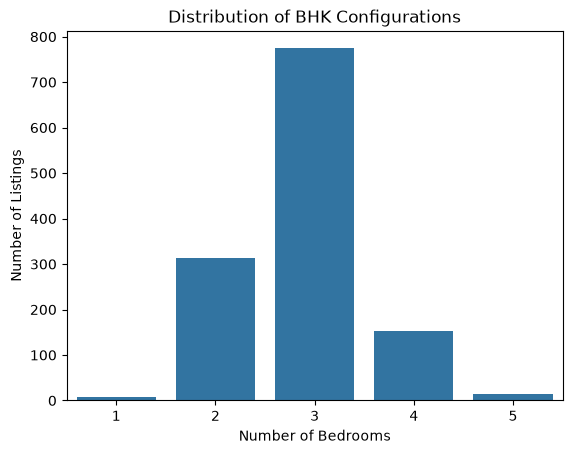

In [6]:
print(df["bhk"].value_counts().sort_index())

sns.countplot(data=df, x="bhk", order=sorted(df["bhk"].unique()))
plt.title("Distribution of BHK Configurations")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Number of Listings")
plt.show()

In [13]:

print(df.columns.tolist())

['property_name', 'property_type', 'location', 'price', 'price_per_sqft', 'area_type', 'area_sqft', 'bhk', 'furnishing', 'bathrooms']


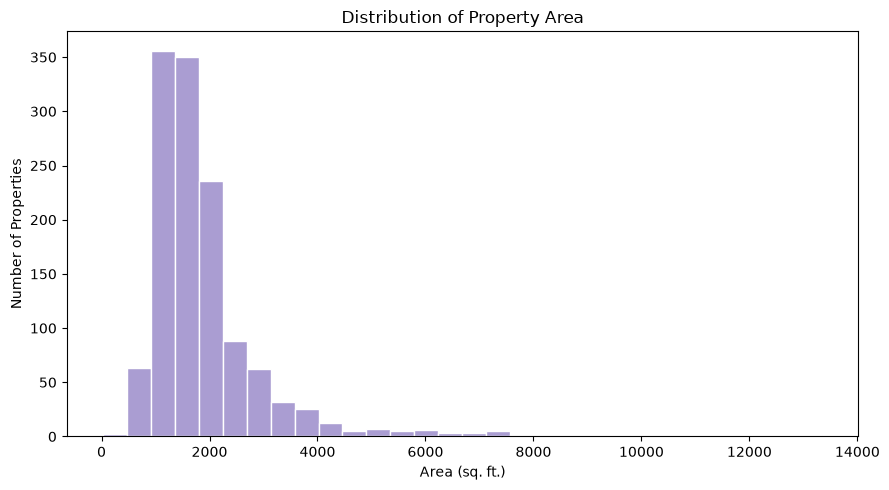

In [15]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="area_sqft",
    bins=30,
    color="#8E7CC3",
    edgecolor="white"
)

plt.title("Distribution of Property Area")
plt.xlabel("Area (sq. ft.)")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.show()

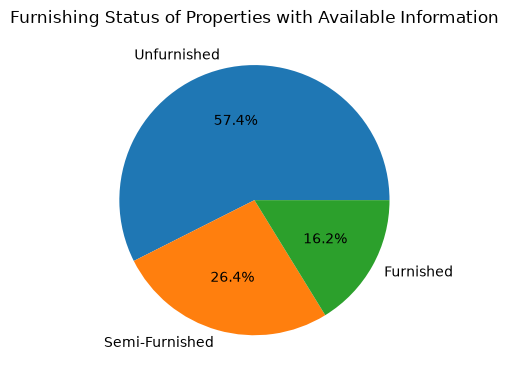

In [8]:

known_furnishing = df[
    df["furnishing"] != "Unknown"
]["furnishing"].value_counts()

plt.figure(figsize=(4,4))

plt.pie(
    known_furnishing,
    labels=known_furnishing.index,
    autopct="%1.1f%%"
)

plt.title("Furnishing Status of Properties with Available Information")
plt.tight_layout()
plt.show()

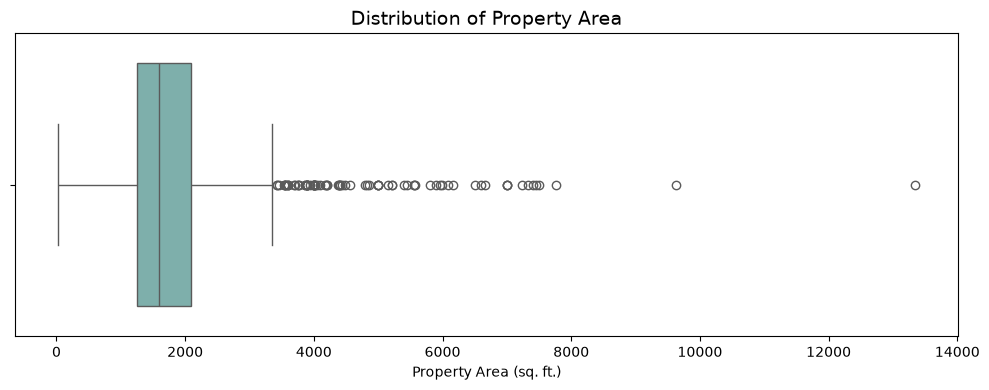

In [22]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="area_sqft",
    color='#76B7B2'
)

plt.title("Distribution of Property Area", fontsize=14)
plt.xlabel("Property Area (sq. ft.)")
plt.tight_layout()
plt.show()

#### Bivariate analysis


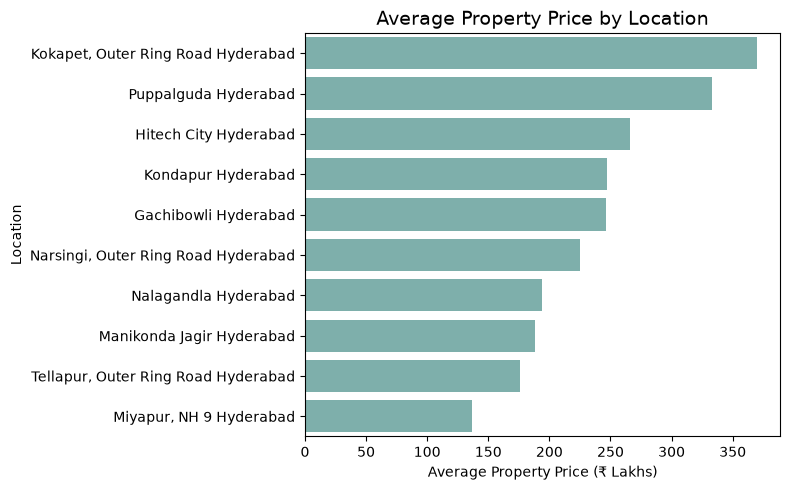

In [12]:
# Select top 10 locations by listing count
top_locations = df["location"].value_counts().head(10).index

# Calculate average property price for each location
location_price = (
    df[df["location"].isin(top_locations)]
    .groupby("location")["price"]
    .mean()
    .div(100000)
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=location_price,
    x="price",
    y="location",
    color="#76B7B2"
)

plt.title("Average Property Price by Location", fontsize=14)
plt.xlabel("Average Property Price (₹ Lakhs)")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

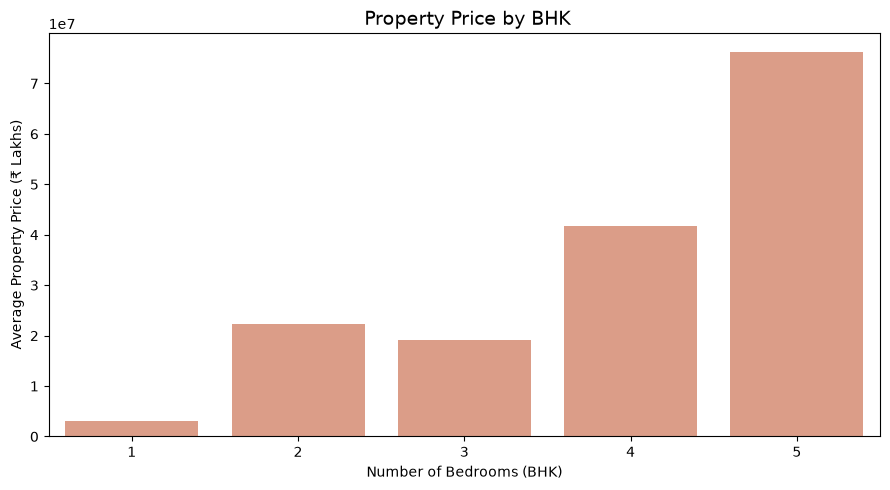

In [9]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="bhk",
    y="price",
    color="#E9967A",
    errorbar=None
)

plt.title(" Property Price by BHK", fontsize=14)
plt.xlabel("Number of Bedrooms (BHK)")
plt.ylabel("Average Property Price (₹ Lakhs)")
plt.tight_layout()
plt.show()

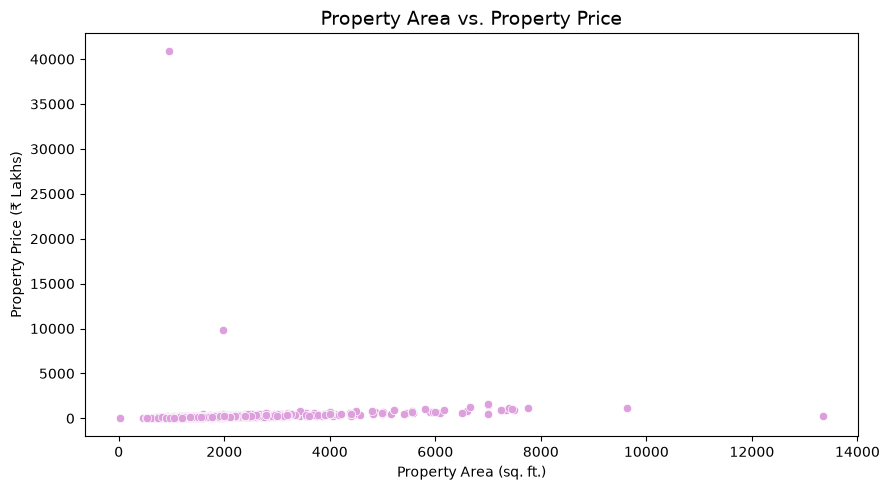

In [11]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="area_sqft",
    y=df["price"] / 100000,
    color="#DDA0DD")

plt.title("Property Area vs. Property Price", fontsize=14)
plt.xlabel("Property Area (sq. ft.)")
plt.ylabel("Property Price (₹ Lakhs)")
plt.tight_layout()
plt.show()

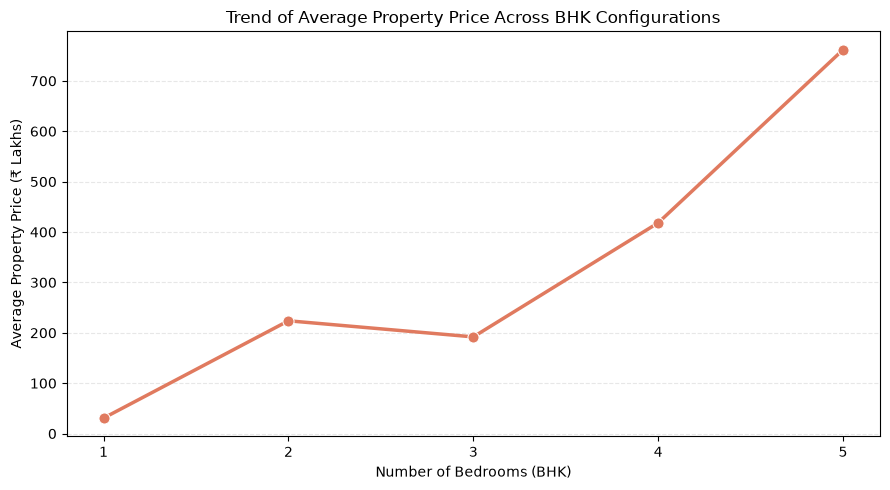

In [37]:
bhk_price = (
    df.groupby("bhk")["price"]
    .mean()
    .div(100000)
    .reset_index()
    .sort_values("bhk")
)

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=bhk_price,
    x="bhk",
    y="price",
    marker="o",
    color="#E07A5F",
    linewidth=2.5,
    markersize=8
)

plt.title("Trend of Average Property Price Across BHK Configurations")
plt.xlabel("Number of Bedrooms (BHK)")
plt.ylabel("Average Property Price (₹ Lakhs)")
plt.xticks(bhk_price["bhk"])
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

#### Multivariate analysis

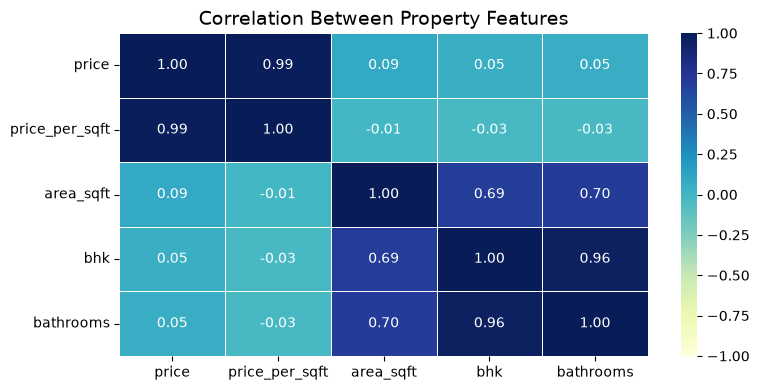

In [13]:
corr_cols = [
    "price",
    "price_per_sqft",
    "area_sqft",
    "bhk",
    "bathrooms"
]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(8, 4))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Property Features", fontsize=14)
plt.tight_layout()
plt.show()

How to interpret it
- Close to +1: strong positive linear association.
- Close to −1: strong negative linear association.
- Close to 0: weak linear association.

### Hypothesis Testing

### Hypothesis 1 – BHK-wise price comparison

Does the average price per square foot differ significantly between 2-BHK and 3-BHK flats?
- Test: Welch's Independent Two-Sample t-test
- Feature: price_per_sqft
- Groups: 2-BHK and 3-BHK

Hypothesis
- H₀: There is no significant difference in the mean price per square foot between 2-BHK and 3-BHK flats.
- H₁: There is a significant difference in the mean price per square foot between 2-BHK and 3-BHK flats.
Significance level: α = 0.05

In [4]:

from scipy.stats import ttest_ind
import pandas as pd
import numpy as np

# Prepare price per square foot values
df["price_per_sqft"] = pd.to_numeric(
    df["price_per_sqft"], errors="coerce"
)

# Select 2-BHK and 3-BHK groups
price_2bhk = df.loc[
    df["bhk"] == 2, "price_per_sqft"
].dropna()

price_3bhk = df.loc[
    df["bhk"] == 3, "price_per_sqft"
].dropna()

# Remove infinite values
price_2bhk = price_2bhk[np.isfinite(price_2bhk)]
price_3bhk = price_3bhk[np.isfinite(price_3bhk)]

# Perform Welch's independent two-sample t-test
t_stat, p_value = ttest_ind(
    price_2bhk,
    price_3bhk,
    equal_var=False
)

print("2-BHK Mean:", price_2bhk.mean())
print("3-BHK Mean:", price_3bhk.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0: There is a significant difference in mean price per sqft.")
else:
    print("Fail to reject H0: Insufficient evidence of a significant difference.")


2-BHK Mean: 21421.945879670282
3-BHK Mean: 9780.226377779001
T-statistic: 0.8479539383754069
P-value: 0.39711082891564564
Fail to reject H0: Insufficient evidence of a significant difference.


### Hypothesis 2: Locality-wise property price comparison
Business question:

Does the average property listing price differ significantly across the top 10 localities in Hyderabad?

Statistical test: One-Way ANOVA

Feature: price

Grouping variable: location

. Hypotheses 
- Null Hypothesis (H₀): There is no statistically significant difference in mean property prices across the selected localities.
- Alternative Hypothesis (H₁): At least one locality has a significantly different mean property price.
Significance level: α = 0.05

In [5]:

from scipy.stats import f_oneway
import numpy as np

# Identify the top 10 localities
top_locations = df["location"].value_counts().head(10).index

# Prepare property price groups
groups = [
    df.loc[df["location"] == loc, "price"].dropna()
    for loc in top_locations
]

# Remove infinite values
groups = [
    group[np.isfinite(group)]
    for group in groups
]

# Perform One-Way ANOVA
f_stat, p_value = f_oneway(*groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0: There is a statistically significant difference in mean property prices across localities.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference in mean property prices across localities.")


F-statistic: 6.42644239886068
P-value: 1.9974834560751195e-08
Reject H0: There is a statistically significant difference in mean property prices across localities.
